# Multiplicación de matrices encadenada

Para calcular $A_1 A_2 \cdots A_n$, donde $A_i$ tiene dimensiones $d_{i-1} \times d_i$, el resultado no depende de dónde se pongan los paréntesis, pero el número de multiplicaciones escalares sí: multiplicar una matriz $p \times q$ por otra $q \times r$ cuesta $p \cdot q \cdot r$. Si $m[i][j]$ es el coste mínimo de $A_i \cdots A_j$ y el último producto se hace partiendo en $k$:

$$m[i][i] = 0, \qquad m[i][j] = \min_{i \le k < j} \left( m[i][k] + m[k+1][j] + d_{i-1}\, d_k\, d_j \right)$$

Hay un número de Catalan de parentizaciones (crece como $4^n$), pero la tabla cuesta $O(n^3)$ en tiempo y $O(n^2)$ en memoria.

## 1. Coste mínimo y parentización

Rellenar $m$ por longitud de cadena creciente guardando en $s[i][j]$ el mejor punto de corte, y escribir la parentización óptima. Probarlo con las seis matrices del ejemplo clásico de Cormen, de dimensiones $30, 35, 15, 5, 10, 20, 25$.

In [1]:
def cadena_matrices(d):
    n = len(d) - 1
    m = [[0] * (n + 1) for _ in range(n + 1)]
    s = [[0] * (n + 1) for _ in range(n + 1)]
    for longitud in range(2, n + 1):
        for i in range(1, n - longitud + 2):
            j = i + longitud - 1
            m[i][j] = float("inf")
            for k in range(i, j):
                coste = m[i][k] + m[k + 1][j] + d[i - 1] * d[k] * d[j]
                if coste < m[i][j]:
                    m[i][j], s[i][j] = coste, k
    return m, s

def parentizacion(s, i, j):
    if i == j:
        return f"A{i}"
    k = s[i][j]
    return f"({parentizacion(s, i, k)}{parentizacion(s, k + 1, j)})"

cormen = [30, 35, 15, 5, 10, 20, 25]
m, s = cadena_matrices(cormen)
print(m[1][6], parentizacion(s, 1, 6))

15125 ((A1(A2A3))((A4A5)A6))


## 2. Comprobación contra fuerza bruta

Generar recursivamente todas las parentizaciones (cada una se parte en un $k$ y se combinan las de los dos lados) con su coste, comprobar que hay un número de Catalan $C_{n-1} = \frac{1}{n}\binom{2n-2}{n-1}$ y que el mínimo coincide con la tabla para dimensiones aleatorias.

In [2]:
import math
import random

def todas(d, i, j):
    # lista de (coste, parentización) de A_i..A_j
    if i == j:
        return [(0, f"A{i}")]
    resultado = []
    for k in range(i, j):
        for c1, p1 in todas(d, i, k):
            for c2, p2 in todas(d, k + 1, j):
                resultado.append((c1 + c2 + d[i - 1] * d[k] * d[j], f"({p1}{p2})"))
    return resultado

opciones = todas(cormen, 1, 6)
print(len(opciones), "parentizaciones; la peor cuesta", max(opciones)[0], "y la mejor", min(opciones)[0])

random.seed(1)
for _ in range(200):
    n = random.randint(1, 8)
    d = [random.randint(1, 30) for _ in range(n + 1)]
    opciones = todas(d, 1, n)
    m, s = cadena_matrices(d)
    assert len(opciones) == math.comb(2 * n - 2, n - 1) // n
    assert min(opciones)[0] == m[1][n]
    assert dict((p, c) for c, p in opciones)[parentizacion(s, 1, n)] == m[1][n]

42 parentizaciones; la peor cuesta 58000 y la mejor 15125


## 3. Multiplicar de verdad con NumPy

Multiplicar matrices enteras aleatorias con NumPy siguiendo la parentización óptima y de izquierda a derecha, contando las multiplicaciones escalares de cada producto. Comprobar que los dos resultados son iguales, que los contadores coinciden con el coste calculado y comparar tiempos.

In [3]:
import time
import numpy as np

def multiplica(matrices, s, i, j, contador):
    if i == j:
        return matrices[i - 1]
    k = s[i][j]
    A, B = multiplica(matrices, s, i, k, contador), multiplica(matrices, s, k + 1, j, contador)
    contador[0] += A.shape[0] * A.shape[1] * B.shape[1]
    return A @ B

def izquierda_a_derecha(matrices, contador):
    resultado = matrices[0]
    for B in matrices[1:]:
        contador[0] += resultado.shape[0] * resultado.shape[1] * B.shape[1]
        resultado = resultado @ B
    return resultado

rng = np.random.default_rng(2)
d = [400, 10, 500, 20, 600, 5, 700]
matrices = [rng.integers(-3, 4, size=(d[i], d[i + 1])) for i in range(len(d) - 1)]
m, s = cadena_matrices(d)

inicio = time.perf_counter()
c_opt = [0]
R1 = multiplica(matrices, s, 1, len(matrices), c_opt)
t_opt = time.perf_counter() - inicio
inicio = time.perf_counter()
c_izq = [0]
R2 = izquierda_a_derecha(matrices, c_izq)
t_izq = time.perf_counter() - inicio

assert np.array_equal(R1, R2) and c_opt[0] == m[1][len(matrices)]
print(parentizacion(s, 1, len(matrices)))
print(f"óptima: {c_opt[0]:>13,} multiplicaciones en {t_opt * 1000:6.1f} ms")
print(f"izquierda a derecha: {c_izq[0]:>13,} multiplicaciones en {t_izq * 1000:6.1f} ms")

((A1(A2(A3(A4A5))))A6)
óptima:     1,555,000 multiplicaciones en    1.0 ms
izquierda a derecha:    13,400,000 multiplicaciones en    5.6 ms


## 4. Memoización frente a tabla

Escribir la recurrencia de arriba abajo con `functools.cache` y comprobar que da lo mismo que la tabla para cadenas aleatorias de hasta 60 matrices. Medir el tiempo de las dos versiones al crecer $n$ y ver que ambas crecen como $n^3$.

In [4]:
from functools import cache

def cadena_memo(d):
    @cache
    def coste(i, j):
        if i == j:
            return 0
        return min(coste(i, k) + coste(k + 1, j) + d[i - 1] * d[k] * d[j] for k in range(i, j))
    return coste(1, len(d) - 1)

random.seed(3)
for _ in range(50):
    d = [random.randint(1, 100) for _ in range(random.randint(2, 61))]
    assert cadena_memo(d) == cadena_matrices(d)[0][1][len(d) - 1]

for n in (50, 100, 200):
    d = [random.randint(1, 100) for _ in range(n + 1)]
    inicio = time.perf_counter()
    cadena_matrices(d)
    t_tabla = time.perf_counter() - inicio
    inicio = time.perf_counter()
    cadena_memo(d)
    t_memo = time.perf_counter() - inicio
    print(f"n = {n:3}: tabla {t_tabla:6.3f} s, memo {t_memo:6.3f} s")

n =  50: tabla  0.002 s, memo  0.005 s


n = 100: tabla  0.017 s, memo  0.034 s


n = 200: tabla  0.135 s, memo  0.269 s


## 5. Dibujar la tabla y el árbol de productos

Dibujar la tabla $m$ del ejemplo de Cormen como mapa de calor (solo tiene sentido el triángulo superior) y, al lado, el árbol de la parentización óptima, con cada producto como un nodo interno.

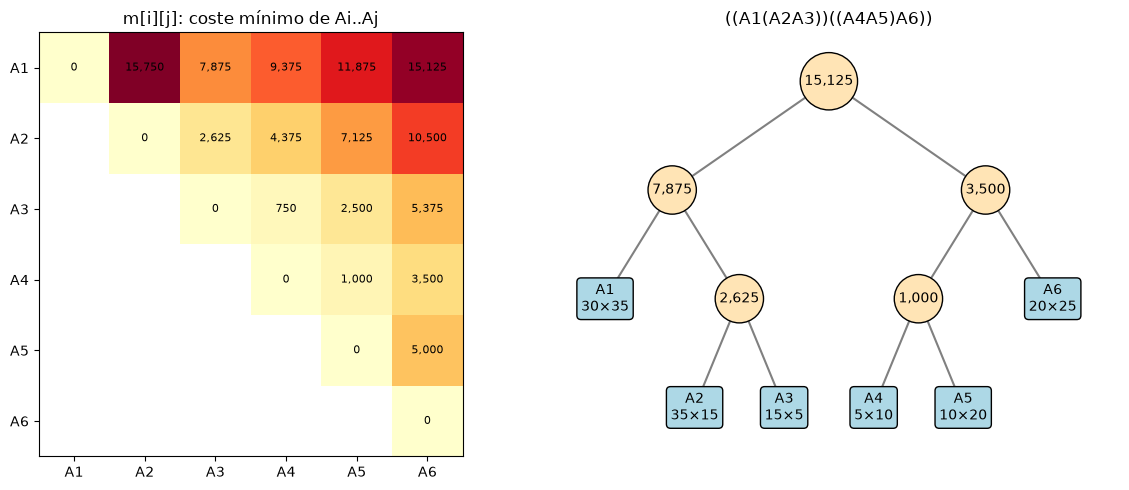

In [5]:
import matplotlib.pyplot as plt

m, s = cadena_matrices(cormen)
n = len(cormen) - 1
fig, (eje1, eje2) = plt.subplots(1, 2, figsize=(12, 5))
datos = np.array([[m[i][j] if j >= i else np.nan for j in range(1, n + 1)] for i in range(1, n + 1)])
eje1.imshow(datos, cmap="YlOrRd")
for i in range(n):
    for j in range(i, n):
        eje1.text(j, i, f"{int(datos[i, j]):,}", ha="center", va="center", fontsize=8)
eje1.set_xticks(range(n), [f"A{j}" for j in range(1, n + 1)])
eje1.set_yticks(range(n), [f"A{i}" for i in range(1, n + 1)])
eje1.set_title("m[i][j]: coste mínimo de Ai..Aj")

def dibuja(i, j, profundidad):
    # devuelve la x del nodo; las hojas se colocan en x = índice de la matriz
    if i == j:
        eje2.text(i, -profundidad, f"A{i}\n{cormen[i - 1]}×{cormen[i]}", ha="center", va="center",
                  bbox=dict(boxstyle="round", facecolor="lightblue"))
        return i
    k = s[i][j]
    x1, x2 = dibuja(i, k, profundidad + 1), dibuja(k + 1, j, profundidad + 1)
    x = (x1 + x2) / 2
    eje2.plot([x, x1], [-profundidad, -profundidad - 1], color="gray", zorder=0)
    eje2.plot([x, x2], [-profundidad, -profundidad - 1], color="gray", zorder=0)
    eje2.text(x, -profundidad, f"{m[i][j]:,}", ha="center", va="center", bbox=dict(boxstyle="circle", facecolor="moccasin"))
    return x

dibuja(1, n, 0)
eje2.set_title(parentizacion(s, 1, n))
eje2.margins(0.15)
eje2.axis("off")
plt.tight_layout()
plt.show()